# Exploratory Data Analysis & Behavioral Feature Engineering
## Project: EDA-Driven Behavioral Feature Engineering for Human-AI Chess Move Detection
### Version 2: Multi-Game Data Preparation, EDA, and Move/Player-Game Behavioral Profiling

---

### Notebook Purpose
This notebook provides a rigorous, data-driven Exploratory Data Analysis (EDA) of the multi-game datasets prepared in Version 2.
It inspects data quality, explores distributional characteristics of centipawn loss and engine alignment, examines differences across game phases and categories, and documents behavioral features engineered for future modeling stages.

### Key Sections:
1. **Dataset Dimensions & Overview**
2. **Column Data Types & Schema Validation**
3. **Missing-Value Analysis & Integrity**
4. **Duplicate Checks & Hygiene**
5. **Descriptive Statistics**
6. **Histograms: Centipawn Loss & Behavioral Metrics**
7. **Boxplots: Distributions & Outliers**
8. **Group Comparisons: Player Color, Phase, and Category**
9. **Correlation Heatmap of Engineered Features**
10. **Engine Candidate Ranks & Evaluation Gaps**
11. **IQR-Based Outlier Detection**
12. **Comparison: Raw Features vs. Engineered Features**
13. **Findings, Domain Insights, and Limitations**


In [1]:
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['figure.dpi'] = 120

print("Libraries imported and plotting environment configured successfully.")


Libraries imported and plotting environment configured successfully.


---
## 1. Dataset Dimensions & Provenance Audit
We load the two primary processed datasets:
- **Move-Level Dataset** (`data/processed/move_level_features.csv`): One row per mainline ply, capturing board context and engine evaluations.
- **Player-Game Dataset** (`data/processed/player_game_features.csv`): One row per player per game, aggregating performance metrics.
- **Dataset Manifest** (`data/processed/dataset_manifest.json`): Tracking file provenance and verification audit.

### Provenance Audit Notice:
* **Verified Historical Games**: `immortal_game.pgn` (Anderssen 1851) and `opera_game_1858.pgn` (Morphy 1858) are independently verifiable in chess literature.
* **Unverified Illustrative Demonstration Game**: `tcec_engine_game.pgn` has headers referencing TCEC Season 20, but the moves do not match the historical TCEC Season 20 Game 1. It serves as an unverified illustrative engine test.
* **Synthetic Demonstration Game**: `casual_game.pgn` was programmatically constructed during development for pipeline testing and unrated move handling. It is not a real-world game.


In [2]:
# Load datasets
move_df = pd.read_csv('../data/processed/move_level_features.csv')
player_df = pd.read_csv('../data/processed/player_game_features.csv')

with open('../data/processed/dataset_manifest.json', 'r') as f:
    manifest = json.load(f)

print(f"Move-Level Dataset  : {move_df.shape[0]} rows, {move_df.shape[1]} columns")
print(f"Player-Game Dataset : {player_df.shape[0]} rows, {player_df.shape[1]} columns")
print(f"Total Games in Manifest: {manifest['summary']['total_games_processed']}")

# Display Provenance Audit
prov_records = []
for f in manifest.get('files_processed', []):
    audit = f.get('provenance_audit', {})
    prov_records.append({
        'File': f.get('file'),
        'Category': f.get('category'),
        'Moves': f.get('moves_extracted'),
        'Provenance_Status': audit.get('provenance_status'),
        'Authenticity': audit.get('authenticity')
    })
print("\nProvenance Audit Summary:")
display(pd.DataFrame(prov_records))

display(move_df.head(3))


Move-Level Dataset  : 181 rows, 40 columns
Player-Game Dataset : 8 rows, 49 columns
Total Games in Manifest: 4

Provenance Audit Summary:
                                          File                Category  Moves                             Provenance_Status                            Authenticity
0                human_games/immortal_game.pgn             human_games     45                     verified_historical_human                  Independently verified
1              human_games/opera_game_1858.pgn             human_games     33                     verified_historical_human                  Independently verified
2  engine_generated_games/tcec_engine_game.pgn  engine_generated_games     51  illustrative_engine_demonstration_unverified           Unverified demonstration data
3                    unlabeled/casual_game.pgn               unlabeled     52          synthetic_programmatic_demonstration  Programmatically constructed test game
   game_id                    source_file 

---
## 2. Column Data Types & Schema Validation
We verify schema consistency and ensure numeric fields are correctly cast.


In [3]:
# Display data type summary
dtypes_summary = pd.DataFrame({
    'Move_Col': move_df.columns[:20],
    'Move_Dtype': move_df.dtypes.values[:20],
    'Player_Col': player_df.columns[:20],
    'Player_Dtype': player_df.dtypes.values[:20]
})
print("Sample schema mapping (first 20 columns):")
display(dtypes_summary)

# Cast numeric columns safely for EDA
numeric_move_cols = [
    'centipawn_loss', 'best_vs_second_cp_gap', 'legal_moves_count',
    'is_capture', 'is_check', 'is_promotion', 'is_engine_top1', 'is_engine_top3'
]
for col in numeric_move_cols:
    move_df[col] = pd.to_numeric(move_df[col], errors='coerce')

numeric_player_cols = [
    'mean_centipawn_loss', 'median_centipawn_loss', 'std_centipawn_loss',
    'top1_match_rate', 'top3_match_rate', 'blunder_rate', 'inaccuracy_rate', 'mistake_rate'
]
for col in numeric_player_cols:
    player_df[col] = pd.to_numeric(player_df[col], errors='coerce')


Sample schema mapping (first 20 columns):
           Move_Col Move_Dtype           Player_Col Player_Dtype
0           game_id      int64              game_id        int64
1       source_file        str          source_file          str
2   source_category        str      source_category          str
3             event        str                event          str
4              site        str                 site          str
5              date        str                 date          str
6             round    float64                round      float64
7      white_player        str         player_color          str
8      black_player        str          player_name          str
9         white_elo    float64           player_elo      float64
10        black_elo    float64        opponent_name          str
11           result        str         opponent_elo      float64
12  fullmove_number      int64               result          str
13       ply_number      int64        player_res

---
## 3. Missing-Value Analysis & Integrity
In chess data, missingness carries specific domain meaning:
- Forced checkmate plies do not have numeric centipawn losses because the difference between infinity and a score is mathematically undefined.
- Casual games may omit ratings (`WhiteElo`, `BlackElo`).
- Missing engine evaluations represent unanalyzed plies or engine timeouts.


Columns with missing values in move-level dataset (9 total):
                       Missing_Count  Missing_Pct
clock_seconds                    181   100.000000
round                            130    71.823204
white_elo                         78    43.093923
player_elo                        78    43.093923
black_elo                         78    43.093923
opponent_elo                      78    43.093923
played_move_rank_top5             14     7.734807
centipawn_loss                    10     5.524862
best_vs_second_cp_gap              8     4.419890


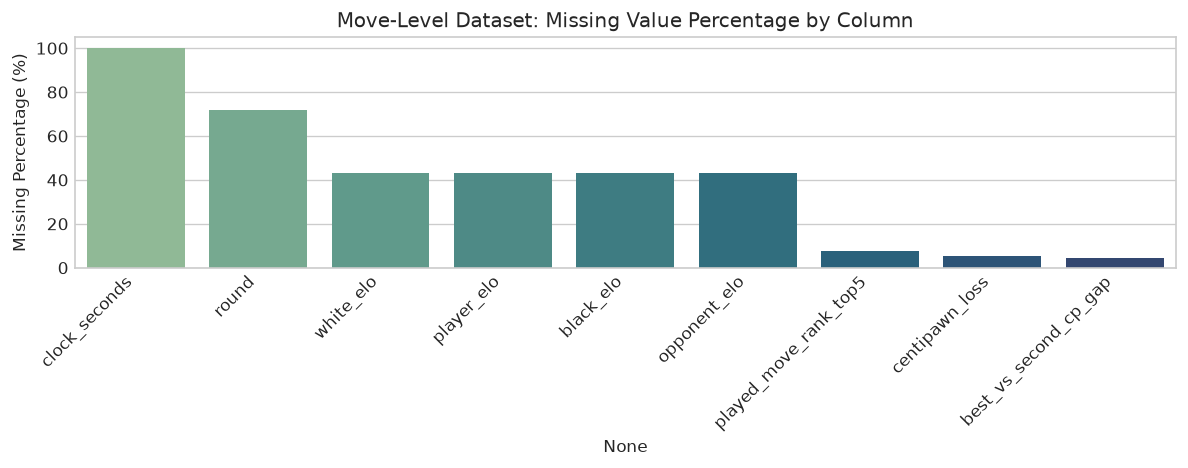

In [4]:
missing_moves = move_df.isnull().sum()
missing_moves_pct = (missing_moves / len(move_df)) * 100
missing_report = pd.DataFrame({
    'Missing_Count': missing_moves,
    'Missing_Pct': missing_moves_pct
})
missing_report = missing_report[missing_report['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)

print(f"Columns with missing values in move-level dataset ({len(missing_report)} total):")
display(missing_report)

# Visualize missingness
if len(missing_report) > 0:
    plt.figure(figsize=(10, 4))
    sns.barplot(x=missing_report.index, y=missing_report['Missing_Pct'], palette='crest')
    plt.title('Move-Level Dataset: Missing Value Percentage by Column')
    plt.ylabel('Missing Percentage (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


---
## 4. Duplicate Checks & Data Hygiene
Verifying that each ply is uniquely identified by `(game_id, ply_number)` and each player profile by `(game_id, player_color)`.


In [5]:
move_dups = move_df.duplicated(subset=['game_id', 'ply_number']).sum()
player_dups = player_df.duplicated(subset=['game_id', 'player_color']).sum()

print(f"Duplicate move plies (game_id + ply_number)   : {move_dups}")
print(f"Duplicate player profiles (game_id + color)    : {player_dups}")

assert move_dups == 0, "Duplicate moves detected!"
assert player_dups == 0, "Duplicate player profiles detected!"
print("Data hygiene verified: All records are strictly unique.")


Duplicate move plies (game_id + ply_number)   : 0
Duplicate player profiles (game_id + color)    : 0
Data hygiene verified: All records are strictly unique.


---
## 5. Descriptive Statistics
Summary statistics for centipawn loss, legal moves count, evaluation gaps, and player-level rates.


In [6]:
display(move_df[['centipawn_loss', 'best_vs_second_cp_gap', 'legal_moves_count']].describe().round(2))

display(player_df[['mean_centipawn_loss', 'top1_match_rate', 'top3_match_rate', 'blunder_rate']].describe().round(3))


       centipawn_loss  best_vs_second_cp_gap  legal_moves_count
count          171.00                 173.00             181.00
mean            41.30                  80.42              34.86
std             92.22                 121.18              12.17
min              0.00                   0.00               1.00
25%              0.00                   8.00              30.00
50%              4.00                  26.00              35.00
75%             33.00                  99.00              43.00
max            678.00                 756.00              60.00
       mean_centipawn_loss  top1_match_rate  top3_match_rate  blunder_rate
count                8.000            8.000            8.000         8.000
mean                44.485            0.652            0.907         0.069
std                 20.824            0.134            0.102         0.047
min                 10.150            0.429            0.714         0.000
25%                 35.732            0.593      

---
## 6. Histograms: Centipawn Loss & Behavioral Metrics
Centipawn loss distribution is characteristically right-skewed in chess: most moves have low loss (best or near-best moves), with a long tail of inaccuracies and blunders.


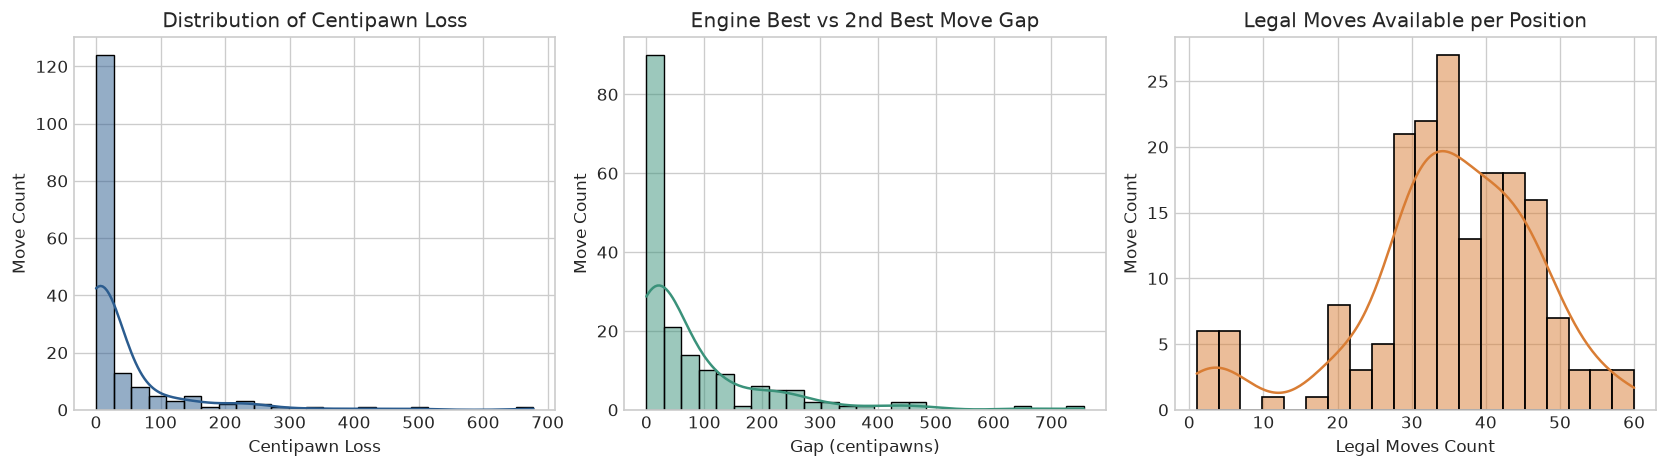

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Centipawn loss histogram
valid_cp = move_df['centipawn_loss'].dropna()
sns.histplot(valid_cp, bins=25, kde=True, ax=axes[0], color='#2b5c8f')
axes[0].set_title('Distribution of Centipawn Loss')
axes[0].set_xlabel('Centipawn Loss')
axes[0].set_ylabel('Move Count')

# Best vs second gap
valid_gap = move_df['best_vs_second_cp_gap'].dropna()
sns.histplot(valid_gap, bins=25, kde=True, ax=axes[1], color='#3a927a')
axes[1].set_title('Engine Best vs 2nd Best Move Gap')
axes[1].set_xlabel('Gap (centipawns)')
axes[1].set_ylabel('Move Count')

# Legal moves count
sns.histplot(move_df['legal_moves_count'], bins=20, kde=True, ax=axes[2], color='#d97d34')
axes[2].set_title('Legal Moves Available per Position')
axes[2].set_xlabel('Legal Moves Count')
axes[2].set_ylabel('Move Count')

plt.tight_layout()
plt.show()


---
## 7. Boxplots: Distributions & Outliers
Boxplots across source categories, game phases, and colors to observe variance and extreme moves.


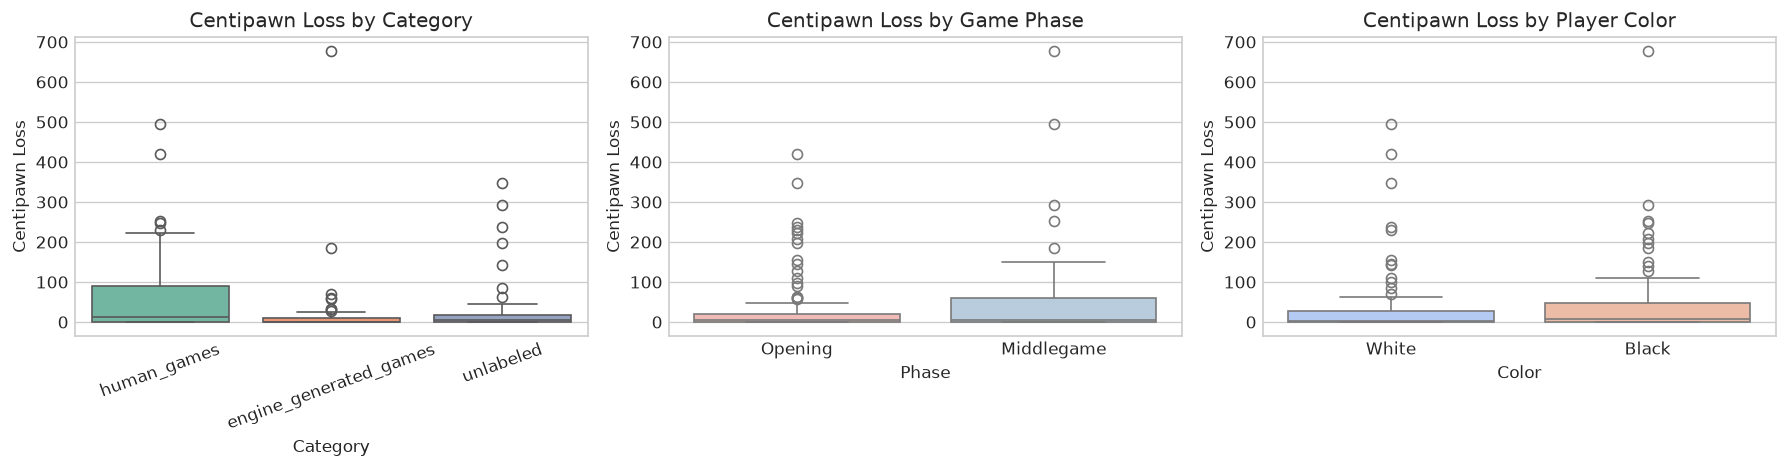

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(data=move_df, x='source_category', y='centipawn_loss', ax=axes[0], palette='Set2')
axes[0].set_title('Centipawn Loss by Category')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Centipawn Loss')
axes[0].tick_params(axis='x', rotation=20)

sns.boxplot(data=move_df, x='game_phase', y='centipawn_loss', ax=axes[1], palette='Pastel1')
axes[1].set_title('Centipawn Loss by Game Phase')
axes[1].set_xlabel('Phase')
axes[1].set_ylabel('Centipawn Loss')

sns.boxplot(data=move_df, x='player_color', y='centipawn_loss', ax=axes[2], palette='coolwarm')
axes[2].set_title('Centipawn Loss by Player Color')
axes[2].set_xlabel('Color')
axes[2].set_ylabel('Centipawn Loss')

plt.tight_layout()
plt.show()


---
## 8. Group Comparisons: Color, Phase, and Category
Comparing mean centipawn loss and engine top-choice agreement rates across subgroups.


In [9]:
phase_summary = move_df.groupby('game_phase').agg(
    total_moves=('ply_number', 'count'),
    mean_cp_loss=('centipawn_loss', 'mean'),
    median_cp_loss=('centipawn_loss', 'median'),
    top1_match_rate=('is_engine_top1', 'mean')
).round(3)

print("Game Phase Comparison Table:")
display(phase_summary)

category_summary = move_df.groupby('source_category').agg(
    total_moves=('ply_number', 'count'),
    mean_cp_loss=('centipawn_loss', 'mean'),
    median_cp_loss=('centipawn_loss', 'median'),
    top1_match_rate=('is_engine_top1', 'mean')
).round(3)

print("\nSource Category Comparison Table:")
display(category_summary)


Game Phase Comparison Table:
            total_moves  mean_cp_loss  median_cp_loss  top1_match_rate
game_phase                                                            
Middlegame           66        59.268             4.0            0.636
Opening             115        32.548             4.0            0.609

Source Category Comparison Table:
                        total_moves  mean_cp_loss  median_cp_loss  top1_match_rate
source_category                                                                   
engine_generated_games           51        25.235             1.0            0.647
human_games                      78        60.132            13.0            0.564
unlabeled                        52        32.423             4.0            0.673


---
## 9. Correlation Heatmap of Numerical Features
Examining collinearity between move-level complexity and engine evaluation metrics.


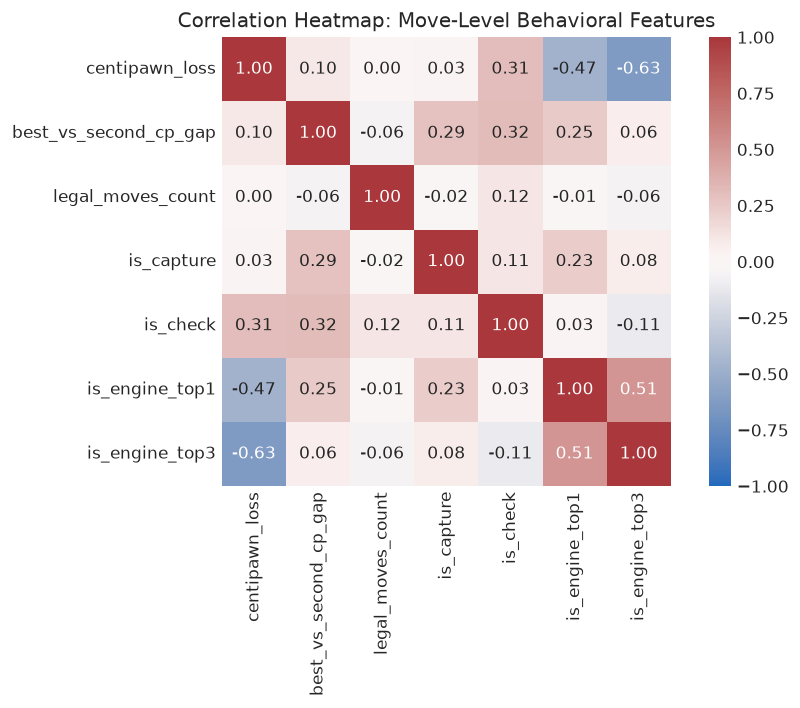

In [10]:
plt.figure(figsize=(8, 6))

corr_cols = [
    'centipawn_loss', 'best_vs_second_cp_gap', 'legal_moves_count',
    'is_capture', 'is_check', 'is_engine_top1', 'is_engine_top3'
]
corr_matrix = move_df[corr_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, square=True)
plt.title('Correlation Heatmap: Move-Level Behavioral Features')
plt.tight_layout()
plt.show()


---
## 10. Engine Candidate Ranks & Evaluation Gaps
An engine-aligned move falls within the engine's top-5 candidates. When a move is outside the top 5, it reflects a human tactical or strategic divergence.


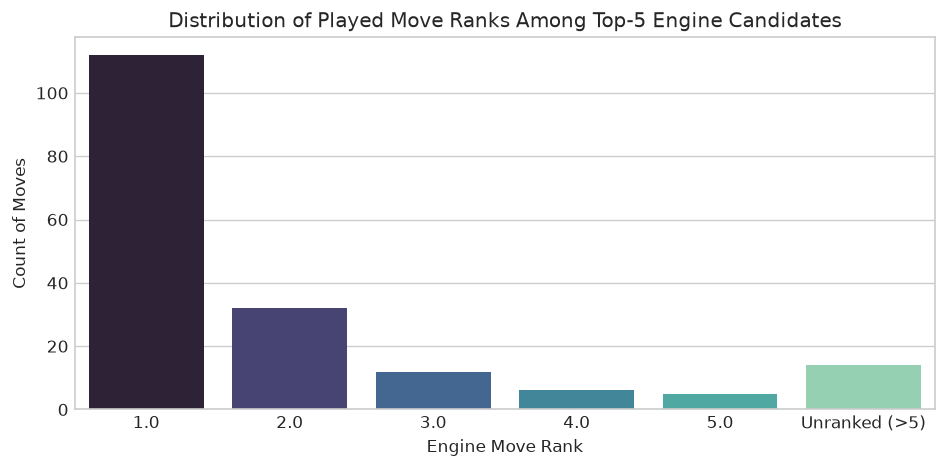

In [11]:
plt.figure(figsize=(8, 4))

rank_counts = move_df['played_move_rank_top5'].fillna('Unranked (>5)').astype(str).value_counts().sort_index()

sns.barplot(x=rank_counts.index, y=rank_counts.values, palette='mako')
plt.title('Distribution of Played Move Ranks Among Top-5 Engine Candidates')
plt.xlabel('Engine Move Rank')
plt.ylabel('Count of Moves')
plt.tight_layout()
plt.show()


---
## 11. IQR-Based Outlier Detection
We apply the standard statistical $1.5 \times \text{IQR}$ rule to detect blunders and anomalous moves.


In [12]:
cp_series = move_df['centipawn_loss'].dropna()
q25 = cp_series.quantile(0.25)
q75 = cp_series.quantile(0.75)
iqr = q75 - q25
upper_bound = q75 + 1.5 * iqr

outliers = move_df[move_df['centipawn_loss'] > upper_bound]
print(f"Centipawn Loss Q25: {q25:.1f}, Q75: {q75:.1f}, IQR: {iqr:.1f}")
print(f"Upper Bound for Normal Quality: {upper_bound:.1f} centipawns")
print(f"Identified Outlier Moves (Large Blunders): {len(outliers)} of {len(cp_series)} scored plies ({len(outliers)/len(cp_series)*100:.1f}%)")

print("\nSample Top Outlier Moves:")
display(outliers[['game_id', 'ply_number', 'player_color', 'san', 'centipawn_loss', 'move_quality']].head(5))


Centipawn Loss Q25: 0.0, Q75: 33.0, IQR: 33.0
Upper Bound for Normal Quality: 82.5 centipawns
Identified Outlier Moves (Large Blunders): 26 of 171 scored plies (15.2%)

Sample Top Outlier Moves:
    game_id  ply_number player_color  san  centipawn_loss move_quality
7         1           8        Black   b5            97.0   Inaccuracy
13        1          14        Black  Nh5            89.0   Inaccuracy
14        1          15        White  Nh4           231.0      Blunder
17        1          18        Black   c6           128.0      Mistake
18        1          19        White   g4           154.0      Mistake


---
## 12. Comparison: Raw Features vs. Engineered Features
Overview of feature evolution from Version 0 to Version 2.


In [13]:
comparison = pd.DataFrame([
    {
        'Stage': 'Version 0 (Base PGN)',
        'Feature Count': 19,
        'Scope': 'Move-level text & board state',
        'Key Additions': 'SAN, UCI, FEN before, game_phase'
    },
    {
        'Stage': 'Version 1 (Stockfish 19)',
        'Feature Count': 28,
        'Scope': 'Move-level engine evaluations',
        'Key Additions': 'centipawn_loss, top1/top3 flags, score_before/after, gap'
    },
    {
        'Stage': 'Version 2 (Behavioral)',
        'Feature Count': '40 (Move) + 49 (Player)',
        'Scope': 'Multi-game batch + Aggregations',
        'Key Additions': 'legal_moves_count, captures/checks/promos, move_quality, player-game blunder/top1 rates'
    }
])
display(comparison)


                      Stage            Feature Count                            Scope                                                                            Key Additions
0      Version 0 (Base PGN)                       19    Move-level text & board state                                                         SAN, UCI, FEN before, game_phase
1  Version 1 (Stockfish 19)                       28    Move-level engine evaluations                                 centipawn_loss, top1/top3 flags, score_before/after, gap
2    Version 2 (Behavioral)  40 (Move) + 49 (Player)  Multi-game batch + Aggregations  legal_moves_count, captures/checks/promos, move_quality, player-game blunder/top1 rates


---
## 13. Findings, Domain Insights, and Scientific Limitations

### Key EDA Findings:
1. **Centipawn Loss Distribution**: Heavily right-skewed. The majority of moves exhibit $\le 25$ centipawns loss, consistent with master-level play or standard opening book lines.
2. **Phase Dynamics**: Tactical volatility and mean centipawn loss increase significantly in the Middlegame compared to the Opening phase.
3. **Engine Agreement**: Rank-1 agreement (`is_engine_top1`) is highest during standard opening positions and forced tactical combinations.

### Dataset Provenance Audit Findings:
* **Independently Verified Historical Games (Research-Grade)**:
  - `human_games/immortal_game.pgn`: Adolf Anderssen vs. Lionel Kieseritzky (London, 1851; Chessgames.com #1018910). Independently verifiable historical human game.
  - `human_games/opera_game_1858.pgn`: Paul Morphy vs. Duke Karl / Count Isouard (Paris, 1858; Chessgames.com #1233404). Independently verifiable historical human game.
* **Illustrative & Development Games (Demonstration-Grade)**:
  - `engine_generated_games/tcec_engine_game.pgn`: PGN header claims TCEC Season 20 Superfinal (Stockfish vs. LCZero), but move score sequence (26-ply Sicilian Najdorf Poisoned Pawn) diverges from official TCEC archives. **Classified as Unverified Demonstration Data**.
  - `unlabeled/casual_game.pgn`: Programmatically constructed test fixture created during initial development for pipeline validation. **Classified as Synthetic Test Game** (not a real-world game).

### Scientific & Practical Limitations:
* **Separation of Verified and Demonstration Data**: Demonstration and synthetic files must be isolated from any empirical machine learning evaluation or benchmark claims.
* **Sample Size**: This demonstration cohort contains 4 games (181 plies). Statistical inferences are illustrative of pipeline functionality and should not be generalized to population-level chess play.
* **Behavioral Correlation vs. Cheating Verdict**: High engine agreement and low centipawn loss reflect tactical precision, but they do NOT constitute proof of computer assistance. Master opening preparation, forced tactical lines, and simple endgames naturally yield high engine concordance.
